# Tufa Labs ARC3 submission

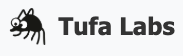

This notebook executes the ARC-AGI-3 solver written by the Tufa Labs team; in alphabetical order: Harold Bessis, Jeroen Cottaar, Isaiah Pressman, Andries Smit, Michal Tesnar, and Stefano Viel.

You will only find infrastructure and diagnostics in this notebook; the actual solver code is in an attached dataset. See our writeup on the competition forum to learn more about that the solver actually does.

It installs the ARC runtime from the competition wheelhouse, makes the bundled source
snapshot importable, runs any solver setup commands, loads the pickled benchmark, plays the
competition games, and writes results to `/kaggle/working`. Diagnostics are minimised during
a real competition rerun (`KAGGLE_IS_COMPETITION_RERUN`) and kept full otherwise.

## 1. Environment and submission mode

Detect whether this is a real competition rerun (which minimises diagnostics), set the
framework's environment flags, and put the CUDA libraries on the linker path.

In [ ]:
import json
import os
import pickle
import subprocess
import sys
import sysconfig
import time
from datetime import datetime, timedelta
from pathlib import Path
from urllib.request import urlopen

# True only inside a real competition rerun; switches diagnostics + soft deadline.
TRUE_SUBMISSION = os.environ.get("KAGGLE_IS_COMPETITION_RERUN", "").strip().lower() in {"1", "true"}
NOTEBOOK_START_EPOCH = time.time()

# Non-interactive matplotlib backend: diagnostics render plots with no display attached.
os.environ["MPLBACKEND"] = "Agg"
# Marks the run as a (real or emulated) submission so the framework + solver can adjust.
os.environ["TAAF_RUN_AS_SUBMISSION"] = "1" if TRUE_SUBMISSION else "0"
# In submission, disable the periodic JSON/HTML diagnostics writes and per-frame logging.
os.environ["TAAF_MINIMAL_DIAGNOSTICS"] = "1" if TRUE_SUBMISSION else "0"
# Pin arc_agi's cached level_reset_only before its client is built (RESET keeps the level).
os.environ["ONLY_RESET_LEVELS"] = "true"

# Prepend the CUDA toolkit to the linker path (it is off it on Kaggle GPU images) so the
# solver's GPU libraries (e.g. vllm / torch) can link against libcuda.
cuda_library_path = "/usr/local/nvidia/lib64"
os.environ["LIBRARY_PATH"] = os.pathsep.join(
    entry for entry in [cuda_library_path, *os.environ.get("LIBRARY_PATH", "").split(os.pathsep)] if entry
)

# Everything the run produces is written here.
WORKING_DIR = Path("/kaggle/working")
WORKING_DIR.mkdir(parents=True, exist_ok=True)
print(f"taaf.kaggle: TRUE_SUBMISSION={TRUE_SUBMISSION}")

## 2. Install the ARC runtime

Install `arc-agi` from the offline competition wheelhouse (the Kaggle submission environment
has no internet).

In [ ]:
# Install the ARC runtime from the bundled competition wheels.
# Quiet: stdout is discarded; stderr (and a non-zero exit) still surface real failures.
subprocess.check_call(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--no-index",
        "--no-warn-conflicts",
        "--disable-pip-version-check",
        "--find-links",
        "/kaggle/input/competitions/arc-prize-2026-arc-agi-3/arc_agi_3_wheels",
        "arc-agi",
    ],
    stdout=subprocess.DEVNULL,
)

## 3. Locate the source bundle

Find the uploaded TAAF source dataset by its marker file, and record where Kaggle mounted
every attached input so setup commands and the solver can find them.

In [ ]:
# Kaggle inputs attached to this notebook, plus bookkeeping paths used below.
DATASET_SOURCES = ["jeroencottaar/taaf-kaggle-source-share", "bilgisarmal/vllm031-cp313-wheelhouse", "driessmit1/qwen3-8-27b-fp8-hf-017b9c7a", "liaojiaxuan/lingjing-duck-franzen-overlay"]
KERNEL_SOURCES = []
DATASET_BUNDLE_MARKER = "taaf-kaggle-bundle.json"
SETUP_ENV_PATH = WORKING_DIR / "taaf_setup_env.json"


# Locate the source dataset by its marker file rather than a fixed mount path.
def _find_bundle_dir() -> Path:
    for marker in Path("/kaggle/input").rglob(DATASET_BUNDLE_MARKER):
        return marker.parent
    raise RuntimeError("TAAF source bundle not found under /kaggle/input.")


# Kaggle mounts a dataset at /kaggle/input/<slug> or /kaggle/input/datasets/<owner>/<slug>
# (depending on owner / slug collisions), so probe both and use whichever exists. Utility
# scripts mount under /kaggle/usr/lib/notebooks/<owner>/<slug>.
def _dataset_mount_candidates(ref: str) -> list[Path]:
    owner, slug = ref.split("/", 1)
    return [Path("/kaggle/input") / slug, Path("/kaggle/input/datasets") / owner / slug]


def _kernel_mount_candidates(ref: str) -> list[Path]:
    owner, slug = ref.split("/", 1)
    return [Path("/kaggle/usr/lib/notebooks") / owner / slug]


def _first_existing(candidates: list[Path]) -> Path | None:
    return next((c for c in candidates if c.exists()), None)


BUNDLE_DIR = _find_bundle_dir()
print(f"taaf.kaggle: source bundle = {BUNDLE_DIR}")

# Map each attached input to where Kaggle actually mounted it (the source bundle is index 0).
kaggle_input_paths: dict[str, str] = {}
for i, ref in enumerate(DATASET_SOURCES):
    candidates = _dataset_mount_candidates(ref)
    resolved = BUNDLE_DIR if i == 0 else _first_existing(candidates)
    kaggle_input_paths[ref] = str(resolved or candidates[0])
for ref in KERNEL_SOURCES:
    candidates = _kernel_mount_candidates(ref)
    kaggle_input_paths[ref] = str(_first_existing(candidates) or candidates[0])

# Published to setup commands and the solver via the environment:
setup_env = {
    # JSON {ref: mount_path} so they can locate every attached dataset / utility script.
    "TAAF_KAGGLE_INPUT_PATHS": json.dumps(kaggle_input_paths, sort_keys=True),
    # The attached dataset refs in order (index 0 is this source bundle).
    "TAAF_KAGGLE_DATASET_SOURCES": json.dumps(DATASET_SOURCES),
    # The attached utility-script / kernel refs.
    "TAAF_KAGGLE_KERNEL_SOURCES": json.dumps(KERNEL_SOURCES),
}
os.environ.update(setup_env)
SETUP_ENV_PATH.write_text(json.dumps(setup_env, indent=2, sort_keys=True) + "\n")
print(f"taaf.kaggle: input paths = {setup_env['TAAF_KAGGLE_INPUT_PATHS']}")


## 4. Import the bundled source and run solver setup

Put the snapshotted repositories on the path (this process and any child processes), then run
the solver's setup commands — installing wheels, fetching model weights, and so on.

In [ ]:
# Each bundled repo exposes its importable tree at <repo>/src or <repo>.
def _source_path_entries(bundle_dir: Path) -> list:
    entries = []
    for repo in sorted((bundle_dir / "src").iterdir(), reverse=True):
        for candidate in (repo / "src", repo):
            if candidate.is_dir():
                entries.append(candidate)
    return entries


# Environment handed to each setup command (paths + any keys it has persisted).
def _command_env() -> dict:
    env = os.environ.copy()
    # "$PYTHON" in a command resolves to this notebook's interpreter.
    env["PYTHON"] = sys.executable
    # Absolute path to the mounted source bundle.
    env["TAAF_KAGGLE_BUNDLE_DIR"] = str(BUNDLE_DIR)
    # The writable /kaggle/working directory.
    env["TAAF_KAGGLE_WORKING_DIR"] = str(WORKING_DIR)
    # A command writes a JSON object here to persist env keys to later commands + the run.
    env["TAAF_KAGGLE_SETUP_ENV"] = str(SETUP_ENV_PATH)
    env.update({str(k): str(v) for k, v in json.loads(SETUP_ENV_PATH.read_text()).items()})
    return env


# Make the bundled repos importable here (sys.path) and in child processes (.pth).
source_entries = _source_path_entries(BUNDLE_DIR)
for entry in source_entries:
    sys.path.insert(0, str(entry))
pth_path = Path(sysconfig.get_paths()["purelib"]) / "taaf_kaggle_sources.pth"
pth_path.write_text("".join(f"{entry}\n" for entry in source_entries))
print(f"taaf.kaggle: wrote {pth_path} ({len(source_entries)} source roots)")

# Solver setup commands (wheels, vLLM server startup, ...) run before the benchmark loads.

# --- lingjing patch: cp313 wheelhouse + Qwen3.8 + Franzen vLLM flags ---
_setup_path = BUNDLE_DIR / "setup_commands.json"
_cmds = json.loads(_setup_path.read_text(encoding="utf-8"))
_patched_cmds = []
_nl = chr(10)
_find_old = "'--find-links'," + _nl + "        str(WHEELHOUSE),"
_find_new = (
    "'--find-links'," + _nl
    + "        str((WHEELHOUSE / 'wheels') if (WHEELHOUSE / 'wheels').is_dir() else WHEELHOUSE),"
)
for _cmd in _cmds:
    if not isinstance(_cmd, str):
        _patched_cmds.append(_cmd)
        continue
    _cmd = _cmd.replace("WHEELHOUSE_OWNER = 'driessmit1'", "WHEELHOUSE_OWNER = 'bilgisarmal'")
    _cmd = _cmd.replace(
        "WHEELHOUSE_SLUG = 'arc3-vllm-h100-wheelhouse-v3'",
        "WHEELHOUSE_SLUG = 'vllm031-cp313-wheelhouse'",
    )
    # Prefer explicit Qwen3.8 snapshot when present in the setup script.
    _cmd = _cmd.replace("MODEL_OWNER = 'driessmit1'", "MODEL_OWNER = 'driessmit1'")
    _cmd = _cmd.replace(
        "MODEL_SLUG = 'vrfai-qwen3-6-27b-fp8-hf-snapshot'",
        "MODEL_SLUG = 'qwen3-8-27b-fp8-hf-017b9c7a'",
    )
    _cmd = _cmd.replace(
        "MODEL_SLUG = 'qwen3-6-27b-fp8-hf-snapshot'",
        "MODEL_SLUG = 'qwen3-8-27b-fp8-hf-017b9c7a'",
    )
    _cmd = _cmd.replace(
        "SERVED_MODEL_NAME = 'vrfai/Qwen3.6-27B-FP8'",
        "SERVED_MODEL_NAME = 'Qwen3.8-27B-FP8'",
    )
    _cmd = _cmd.replace(
        "SERVED_MODEL_NAME = 'Qwen3.6-27B-FP8'",
        "SERVED_MODEL_NAME = 'Qwen3.8-27B-FP8'",
    )
    # Franzen: larger board images.
    _cmd = _cmd.replace("MULTIMODAL_UPSCALE', '4'", "MULTIMODAL_UPSCALE', '10'")
    _cmd = _cmd.replace('MULTIMODAL_UPSCALE", "4"', 'MULTIMODAL_UPSCALE", "10"')
    _cmd = _cmd.replace("MULTIMODAL_UPSCALE = '4'", "MULTIMODAL_UPSCALE = '10'")
    # Upstream writes the setup_env dict with a colon: 'MULTIMODAL_UPSCALE': '4'.
    _cmd = _cmd.replace("MULTIMODAL_UPSCALE': '4'", "MULTIMODAL_UPSCALE': '10'")
    if _find_old not in _cmd:
        raise RuntimeError("find-links pattern missing in setup command")
    _cmd = _cmd.replace(_find_old, _find_new)
    _vllm_marker = "'--max-model-len'," + _nl + "        str(VLLM_MAX_MODEL_LEN),"
    _vllm_extra = (
        _vllm_marker + _nl
        + "        '--enforce-eager'," + _nl
        + "        '--linear-backend'," + _nl
        + "        'cutlass'," + _nl
        + "        '--max-num-seqs'," + _nl
        + "        '8',"
    )
    if _vllm_marker not in _cmd:
        raise RuntimeError("vLLM max-model-len marker missing in setup command")
    if "'--enforce-eager'" not in _cmd:
        _cmd = _cmd.replace(_vllm_marker, _vllm_extra, 1)
    # Ensure admit limit is 8 even if upstream already shipped enforce-eager.
    for _old_seqs in ("'16'", "'4'", "'28'", "'32'"):
        _seq_pat = "'--max-num-seqs'," + _nl + "        " + _old_seqs
        if _seq_pat in _cmd:
            _cmd = _cmd.replace(
                _seq_pat,
                "'--max-num-seqs'," + _nl + "        '8'",
                1,
            )
            break
    else:
        if "'--max-num-seqs'," not in _cmd:
            _cmd = _cmd.replace(
                _vllm_marker,
                _vllm_marker + _nl + "        '--max-num-seqs'," + _nl + "        '8'",
                1,
            )
    # 64k + 8 concurrent multimodal jobs OOMs on a single RTX Pro 6000 FP8;
    # Franzen analyzer tier that fits is 32k (same as SmartRouter ctx32768).
    _cmd = _cmd.replace(
        "VLLM_MAX_MODEL_LEN = 65536",
        "VLLM_MAX_MODEL_LEN = 32768",
    )
    if "min(int(VLLM_MAX_MODEL_LEN), 32768)" not in _cmd:
        _cmd = _cmd.replace(
            "str(VLLM_MAX_MODEL_LEN)",
            "str(min(int(VLLM_MAX_MODEL_LEN), 32768))",
            1,
        )
    # Qwen 27B FP8 on Kaggle NFS often needs >15 min to prefetch (~33GB).
    # Stock wait_for_vllm_server default is 900s — same failure mode as SmartRouter v14.
    _cmd = _cmd.replace(
        "timeout_seconds: int = 900",
        "timeout_seconds: int = 2400",
    )
    _cmd = _cmd.replace(
        "wait_for_vllm_server()",
        "wait_for_vllm_server(timeout_seconds=2400)",
    )
    # Prefer Triton GDN, but only if this vLLM build actually accepts the flag:
    # an unrecognized argument aborts the api_server before it binds the port,
    # which would waste the whole run. Probe --help once (~15s) and fall back to
    # the SmartRouter-proven config (no flag) when unsupported.
    # NOTE: the replaced print() line keeps its own 4-space indent, so continuation
    # lines below must start at 8 spaces (12 inside the nested if).
    if "'--gdn-prefill-backend'" not in _cmd:
        _cmd = _cmd.replace(
            "print('Starting vLLM OpenAI server:', ' '.join(cmd), flush=True)",
            (
                "if '--gdn-prefill-backend' not in cmd:" + _nl
                + "        _hp = subprocess.run([sys.executable, '-m'," + _nl
                + "            'vllm.entrypoints.openai.api_server', '--help']," + _nl
                + "            capture_output=True, text=True, env=vllm_env())" + _nl
                + "        if '--gdn-prefill-backend' in (_hp.stdout or '') + (_hp.stderr or ''):" + _nl
                + "            cmd.extend(['--gdn-prefill-backend', 'triton'])" + _nl
                + "            print('LINGJING_GDN_TRITON_OK', flush=True)" + _nl
                + "        else:" + _nl
                + "            print('LINGJING_GDN_TRITON_UNSUPPORTED', flush=True)" + _nl
                + "    print('Starting vLLM OpenAI server:', ' '.join(cmd), flush=True)"
            ),
            1,
        )
    _cmd = _cmd.replace(
        "os.environ.get('VLLM_USE_FLASHINFER_SAMPLER', '1')",
        "'0'",
    )
    _cmd = _cmd.replace(
        "'VLLM_USE_FLASHINFER_SAMPLER': '1'",
        "'VLLM_USE_FLASHINFER_SAMPLER': '0'",
    )
    # Upstream never sets the sampler env at all; inject it into vllm_env() and the
    # persisted setup_env so the SM12x FlashInfer top-p/top-k fallback stays silent
    # (Duck 10-13 log: "FlashInfer top-p/top-k sampling unavailable ... falling back").
    _cmd = _cmd.replace(
        "'VLLM_NO_USAGE_STATS': '1',",
        "'VLLM_NO_USAGE_STATS': '1'," + _nl + "            'VLLM_USE_FLASHINFER_SAMPLER': '0',",
    )
    # Thinking traces dominate decode time on a single GPU. Cap output too.
    _cmd = _cmd.replace(
        "'LOCAL_ANALYZER_ENABLE_THINKING': 'true'",
        "'LOCAL_ANALYZER_ENABLE_THINKING': 'false'",
    )
    _cmd = _cmd.replace(
        "'LOCAL_ANALYZER_ENABLE_THINKING': '1'",
        "'LOCAL_ANALYZER_ENABLE_THINKING': '0'",
    )
    # Avoid braces here — this block is an f-string.
    _cmd = _cmd.replace('"preserve_thinking": true', '"preserve_thinking": false')
    _cmd = _cmd.replace("'preserve_thinking': true", "'preserve_thinking': false")
    _cmd = _cmd.replace(
        "'LOCAL_ANALYZER_MAX_OUTPUT': '0'",
        "'LOCAL_ANALYZER_MAX_OUTPUT': '1536'",
    )
    _cmd = _cmd.replace(
        "'LOCAL_ANALYZER_TOOL_STEPS': '0'",
        "'LOCAL_ANALYZER_TOOL_STEPS': '3'",
    )
    _cmd = _cmd.replace(
        "'LOCAL_ANALYZER_YIELD_SECONDS': '60'",
        "'LOCAL_ANALYZER_YIELD_SECONDS': '20'",
    )
    # Admit limit already pinned to 8 above (matches solver.concurrency).
    # Torch 2.10 needs libcudart.so.13 from nvidia-cuda-runtime; pip --target often
    # leaves those .so files off the dynamic linker path. Extract + LD_LIBRARY_PATH.
    # NOTE: this whole inject block is an f-string — literal braces must be doubled.
    _vllm_env_marker = (
        "def vllm_env() -> dict[str, str]:" + _nl
        + "    env = os.environ.copy()" + _nl
        + "    existing = env.get('PYTHONPATH', '')" + _nl
        + "    env['PYTHONPATH'] = str(SITE_PACKAGES) if not existing else f'{SITE_PACKAGES}{os.pathsep}{existing}'" + _nl
        + "    env.update("
    )
    _vllm_env_hook = (
        "def vllm_env() -> dict[str, str]:" + _nl
        + "    env = os.environ.copy()" + _nl
        + "    existing = env.get('PYTHONPATH', '')" + _nl
        + "    env['PYTHONPATH'] = str(SITE_PACKAGES) if not existing else f'{SITE_PACKAGES}{os.pathsep}{existing}'" + _nl
        + "    _lib_dirs: list[str] = []" + _nl
        + "    _seen: set[str] = set()" + _nl
        + "    def _add_lib(_p: Path) -> None:" + _nl
        + "        _s = str(_p)" + _nl
        + "        if _s and _s not in _seen and Path(_s).is_dir():" + _nl
        + "            _seen.add(_s)" + _nl
        + "            _lib_dirs.append(_s)" + _nl
        + "    # torch/lib first — we copy libcudart here so the linker always finds it" + _nl
        + "    _add_lib(SITE_PACKAGES / 'torch' / 'lib')" + _nl
        + "    _add_lib(SITE_PACKAGES / '_lingjing_cuda_libs')" + _nl
        + "    _add_lib(SITE_PACKAGES / 'nvidia' / 'cu13' / 'lib')" + _nl
        + "    _add_lib(SITE_PACKAGES / 'nvidia' / 'cuda_runtime' / 'lib')" + _nl
        + "    for _hit in SITE_PACKAGES.rglob('libcudart.so*'):" + _nl
        + "        _add_lib(_hit.parent)" + _nl
        + "    _nvidia = SITE_PACKAGES / 'nvidia'" + _nl
        + "    if _nvidia.is_dir():" + _nl
        + "        for _p in _nvidia.rglob('*'):" + _nl
        + "            if _p.is_dir() and _p.name in ('lib', 'lib64'):" + _nl
        + "                _add_lib(_p)" + _nl
        + "    for _sys in (Path('/usr/local/nvidia/lib64'), Path('/usr/local/cuda/lib64')):" + _nl
        + "        _add_lib(_sys)" + _nl
        + "    _old_ld = env.get('LD_LIBRARY_PATH', '')" + _nl
        + "    env['LD_LIBRARY_PATH'] = os.pathsep.join([*_lib_dirs, *([_old_ld] if _old_ld else [])])" + _nl
        + "    print('LINGJING_LD_LIBRARY_PATH_V2', env['LD_LIBRARY_PATH'][:1200], flush=True)" + _nl
        + "    env.update("
    )
    # Force V2 even if an older LD hook was somehow present.
    if "LINGJING_LD_LIBRARY_PATH_V2" not in _cmd:
        if "LINGJING_LD_LIBRARY_PATH" in _cmd and _vllm_env_marker not in _cmd:
            # Already patched once; leave as-is and rely on torch/lib cudart copy.
            pass
        elif _vllm_env_marker not in _cmd:
            raise RuntimeError("vllm_env marker missing in setup command")
        else:
            _cmd = _cmd.replace(_vllm_env_marker, _vllm_env_hook, 1)
    # Persist LD_LIBRARY_PATH into taaf setup env for the solver process.
    _setup_env_marker = (
        "setup_env = {" + _nl
        + "    'USE_TF': '0',"
    )
    _setup_env_hook = (
        "setup_env = {" + _nl
        + "    'LD_LIBRARY_PATH': vllm_env().get('LD_LIBRARY_PATH', '')," + _nl
        + "    'USE_TF': '0',"
    )
    if "'LD_LIBRARY_PATH': vllm_env()" not in _cmd:
        if _setup_env_marker not in _cmd:
            raise RuntimeError("setup_env marker missing in setup command")
        _cmd = _cmd.replace(_setup_env_marker, _setup_env_hook, 1)
    # Ensure cudart + cutlass before launching vLLM.
    _start_marker = (
        "def start_vllm_server() -> None:" + _nl
        + "    install_vllm_wheelhouse()"
    )
    _start_hook = (
        "def start_vllm_server() -> None:" + _nl
        + "    install_vllm_wheelhouse()" + _nl
        + "    import shutil as _shutil" + _nl
        + "    import zipfile as _zipfile" + _nl
        + "    _wh = (WHEELHOUSE / 'wheels') if (WHEELHOUSE / 'wheels').is_dir() else WHEELHOUSE" + _nl
        + "    _pkgs = []" + _nl
        + "    for _whl in sorted(_wh.glob('nvidia*.whl')):" + _nl
        + "        _stem = _whl.name.split('-')[0].replace('_', '-')" + _nl
        + "        if _stem not in _pkgs:" + _nl
        + "            _pkgs.append(_stem)" + _nl
        + "    print('LINGJING_NVIDIA_PKGS', _pkgs, flush=True)" + _nl
        + "    if _pkgs:" + _nl
        + "        subprocess.run([" + _nl
        + "            sys.executable, '-m', 'pip', 'install', '--no-index'," + _nl
        + "            '--find-links', str(_wh), '--target', str(SITE_PACKAGES)," + _nl
        + "            '--upgrade', '--ignore-installed', '--only-binary', ':all:'," + _nl
        + "            '--no-compile', '--disable-pip-version-check', '--no-warn-conflicts'," + _nl
        + "            *_pkgs," + _nl
        + "        ], check=False)" + _nl
        + "    print('CUTLASS_DSL_INSTALL_DONE', flush=True)" + _nl
        + "    # Put every NVIDIA .so next to torch so the dynamic linker finds cupti/cudart/cublas." + _nl
        + "    _torch_lib = SITE_PACKAGES / 'torch' / 'lib'" + _nl
        + "    _torch_lib.mkdir(parents=True, exist_ok=True)" + _nl
        + "    _nlink = 0" + _nl
        + "    _nvidia_root = SITE_PACKAGES / 'nvidia'" + _nl
        + "    if _nvidia_root.is_dir():" + _nl
        + "        for _so in _nvidia_root.rglob('*'):" + _nl
        + "            if not _so.is_file() or '.so' not in _so.name:" + _nl
        + "                continue" + _nl
        + "            _dest = _torch_lib / _so.name" + _nl
        + "            if _dest.exists() or _dest.is_symlink():" + _nl
        + "                continue" + _nl
        + "            try:" + _nl
        + "                _dest.symlink_to(_so)" + _nl
        + "            except OSError:" + _nl
        + "                _shutil.copy2(_so, _dest)" + _nl
        + "            _nlink += 1" + _nl
        + "    if not any(_torch_lib.glob('libcupti.so*')):" + _nl
        + "        for _whl in sorted(_wh.glob('nvidia_cuda_cupti*.whl')):" + _nl
        + "            print('LINGJING_EXTRACT_CUPTI', _whl, flush=True)" + _nl
        + "            with _zipfile.ZipFile(_whl) as _zf:" + _nl
        + "                for _name in _zf.namelist():" + _nl
        + "                    _base = _name.split('/')[-1]" + _nl
        + "                    if _base.startswith('libcupti'):" + _nl
        + "                        (_torch_lib / _base).write_bytes(_zf.read(_name))" + _nl
        + "                        print('LINGJING_CUPTI_WROTE', _base, flush=True)" + _nl
        + "    print('LINGJING_SO_LINK', _nlink, 'cupti', any(_torch_lib.glob('libcupti.so*')), 'cudart', any(_torch_lib.glob('libcudart.so*')), flush=True)" + _nl
        + "    if not any(_torch_lib.glob('libcudart.so*')) or not any(_torch_lib.glob('libcupti.so*')):" + _nl
        + "        raise RuntimeError('LINGJING_CUDA_LIBS_MISSING torch/lib lacks cudart or cupti')" + _nl
        + "    _probe = subprocess.run(" + _nl
        + "        [sys.executable, '-c', 'import torch; print(torch.__version__, torch.version.cuda)']," + _nl
        + "        env=vllm_env(), text=True, capture_output=True," + _nl
        + "    )" + _nl
        + "    print('LINGJING_TORCH_PROBE', _probe.returncode, _probe.stdout.strip(), (_probe.stderr or '')[-500:], flush=True)" + _nl
        + "    if _probe.returncode != 0:" + _nl
        + "        raise RuntimeError('LINGJING_TORCH_IMPORT_FAIL ' + (_probe.stderr or _probe.stdout))"
    )
    if "LINGJING_SO_LINK" not in _cmd:
        if _start_marker not in _cmd:
            raise RuntimeError("start_vllm_server/install marker missing")
        _cmd = _cmd.replace(_start_marker, _start_hook, 1)
    _patched_cmds.append(_cmd)
_cmds_file = WORKING_DIR / "_setup_commands.lingjing.json"
try:
    _setup_path.write_text(json.dumps(_patched_cmds, indent=2), encoding="utf-8")
    _cmds_file = _setup_path
except OSError:
    _cmds_file.write_text(json.dumps(_patched_cmds, indent=2), encoding="utf-8")
print("taaf.kaggle: lingjing patched setup ->", _cmds_file, "n=", len(_patched_cmds), flush=True)
assert "wheels" in _patched_cmds[0], "wheels retarget missing from patched setup"

# Apply Franzen overlay (patched inference modules) ahead of the stock bundle.
import shutil as _shutil
import zipfile as _zipfile
_overlay_root = None
for _cand in (
    Path("/kaggle/input/lingjing-duck-franzen-overlay"),
    Path("/kaggle/input/datasets/liaojiaxuan/lingjing-duck-franzen-overlay"),
):
    if _cand.is_dir():
        _overlay_root = _cand
        break
if _overlay_root is None:
    for _p in Path("/kaggle/input").rglob("LINGJING_OVERLAY.txt"):
        _overlay_root = _p.parent
        break
if _overlay_root is None:
    raise SystemExit("LINGJING_OVERLAY_MISSING attach liaojiaxuan/lingjing-duck-franzen-overlay")
_src_inference = _overlay_root / "inference"
if not _src_inference.is_dir():
    _zip_path = _overlay_root / "inference.zip"
    if not _zip_path.is_file():
        raise SystemExit("LINGJING_OVERLAY_NO_INFERENCE path=%s" % _overlay_root)
    _unzip = WORKING_DIR / "_lingjing_overlay_unzip"
    if _unzip.exists():
        _shutil.rmtree(_unzip)
    _unzip.mkdir(parents=True)
    with _zipfile.ZipFile(_zip_path) as _zf:
        _zf.extractall(_unzip)
    _src_inference = _unzip / "inference"
    if not _src_inference.is_dir():
        # zip may contain files at root of archive
        _hits = list(_unzip.rglob("action_names.py"))
        if not _hits:
            raise SystemExit("LINGJING_OVERLAY_BAD_ZIP")
        _src_inference = _hits[0].parents[1]  # .../inference/agent/file -> inference
# Merge patched modules onto a full copy of stock inference.
# Putting the partial overlay alone on sys.path hides inference.utils.
_stock_inference = None
for _entry in source_entries:
    _cand_inf = Path(_entry) / "inference"
    if (_cand_inf / "utils").is_dir() and (_cand_inf / "agent").is_dir():
        _stock_inference = _cand_inf
        break
if _stock_inference is None:
    raise SystemExit("LINGJING_STOCK_INFERENCE_MISSING")
_overlay_dst = WORKING_DIR / "lingjing_franzen_inference"
if _overlay_dst.exists():
    _shutil.rmtree(_overlay_dst)
_shutil.copytree(_stock_inference, _overlay_dst / "inference")
_copied = 0
for _f in _src_inference.rglob("*"):
    if not _f.is_file():
        continue
    _rel = _f.relative_to(_src_inference)
    _dest = _overlay_dst / "inference" / _rel
    _dest.parent.mkdir(parents=True, exist_ok=True)
    _shutil.copy2(_f, _dest)
    _copied += 1
# Heal nested triple-quote docstrings that break outer raw/setup templates.
_qq = chr(34) * 3
_sq = chr(39) * 3
_heal = [
    (
        _overlay_dst / "inference" / "agent" / "python_tool_sandbox.py",
        _qq + "Compact object-level diff (Franzen). Defaults to previous" + chr(8594) + "current." + _qq,
        _sq + "Compact object-level diff (Franzen). Defaults to previous->current." + _sq,
    ),
    (
        _overlay_dst / "inference" / "agent" / "python_tool_sandbox.py",
        _qq + "Compact object-level diff (Franzen). Defaults to previous->current." + _qq,
        _sq + "Compact object-level diff (Franzen). Defaults to previous->current." + _sq,
    ),
    (
        _overlay_dst / "inference" / "framework" / "kaggle.py",
        _qq + "FlashInfer GDN does `import cutlass`; wheelhouse ships nvidia-cutlass-dsl*." + _qq,
        _sq + "FlashInfer GDN does import cutlass; wheelhouse ships nvidia-cutlass-dsl*." + _sq,
    ),
]
_healed = 0
for _path, _old, _new in _heal:
    if not _path.is_file():
        continue
    _txt = _path.read_text(encoding="utf-8")
    if _old in _txt:
        _path.write_text(_txt.replace(_old, _new), encoding="utf-8")
        _healed += 1
print("taaf.kaggle: overlay docstring heals", _healed, flush=True)
_sys_parent = str(_overlay_dst)
if _sys_parent not in sys.path:
    sys.path.insert(0, _sys_parent)
if pth_path.is_file():
    _prev = pth_path.read_text(encoding="utf-8")
    if _sys_parent not in _prev.splitlines():
        pth_path.write_text(_sys_parent + chr(10) + _prev, encoding="utf-8")
(_overlay_dst / "LINGJING_OVERLAY_APPLIED.txt").write_text(
    ("overlay=%s" + chr(10) + "stock=%s" + chr(10) + "copied=%s" + chr(10) + "served=Qwen3.8-27B-FP8" + chr(10))
    % (_overlay_root, _stock_inference, _copied),
    encoding="utf-8",
)
print("taaf.kaggle: Franzen overlay merged", _overlay_dst, "files", _copied, flush=True)
os.environ["LINGJING_DISABLE_WORLD_MODEL"] = "1"
os.environ["MULTIMODAL_UPSCALE"] = "10"

env = _command_env()
for command in json.loads(_cmds_file.read_text(encoding="utf-8")):

    print(f"taaf.kaggle: setup command: {command}", flush=True)
    subprocess.run(command, shell=True, check=True, cwd=WORKING_DIR, env=env)
    # Re-read in case the command persisted new env keys.
    env = _command_env()
    os.environ.update(env)

# Honour any PYTHONPATH a setup command exported.
for entry in reversed([e for e in os.environ.get("PYTHONPATH", "").split(os.pathsep) if e]):
    if entry not in sys.path:
        sys.path.insert(0, entry)


## 5. Load the benchmark

Unpickle the deployment target and the benchmark, stamping the real submission state onto the
target and pointing the benchmark's outputs at the Kaggle working directory.

In [ ]:
# Restore the deployment target and record the real submission state on it.
with open(BUNDLE_DIR / "deploy_target.pkl", "rb") as file:
    target = pickle.load(file)
target.actual_run_as_submission = TRUE_SUBMISSION
target.is_competition_rerun = TRUE_SUBMISSION

# Restore the benchmark and point its outputs at the Kaggle working dir.
with open(BUNDLE_DIR / "benchmark_initial.pkl", "rb") as file:
    bm = pickle.load(file)
bm.job_dir = WORKING_DIR

## 6. Customization hook

Optional: tweak `bm`, `bm.games`, or `bm.solver` here before the run starts — the safe place
for one-off experiments once the deployed bundle has loaded.

In [ ]:
# lingjing: single-GPU score budget (8-way + 32k ctx, thinking off).
import os as _lj_os
_lj_os.environ['LOCAL_ANALYZER_ENABLE_THINKING'] = '0'
_lj_os.environ['LOCAL_ANALYZER_MAX_OUTPUT'] = '1536'
_lj_os.environ['LOCAL_ANALYZER_TOOL_STEPS'] = '3'
_lj_os.environ['LOCAL_ANALYZER_YIELD_SECONDS'] = '20'
_lj_os.environ['LOCAL_ANALYZER_CONTEXT_WINDOW'] = '32768'
bm.solver.concurrency = 8
bm.solver.max_runtime_s_per_game = 5400
bm.solver.analyzer_timeout = 240
import inference.agent.tool_agent as _lj_ta
_lj_ta._LOCAL_ANALYZER_ENABLE_THINKING = False
_lj_ta._LOCAL_ANALYZER_MAX_OUTPUT = 1536
_lj_ta._LOCAL_ANALYZER_TOOL_STEPS = 3
_lj_ta._LOCAL_ANALYZER_YIELD_SECONDS = 20.0
print('LINGJING_BUDGET', bm.solver.concurrency, bm.solver.max_runtime_s_per_game, bm.solver.analyzer_timeout, 'think', _lj_ta._LOCAL_ANALYZER_ENABLE_THINKING, 'ctx', _lj_os.environ.get('LOCAL_ANALYZER_CONTEXT_WINDOW'), flush=True)
# Make one-off changes to `bm`, `bm.games`, or `bm.solver` here before the run starts.
# Example:
# bm.label = f"{bm.label}-debug"


## 7. Run the benchmark

In a real competition rerun (`KAGGLE_IS_COMPETITION_RERUN`), wait for the Kaggle gateway and
play the **live competition Arcade**. Otherwise — an interactive "Save & Run" — play the
competition's **bundled environment files offline**, with no gateway required, so the notebook
runs end-to-end without a submission. Teardown commands run afterward even if the run raises.

In [ ]:
# Build the live competition game list from the gateway's available environments.
def _competition_games():
    import arc_agi

    import taaf.game_api

    spec = taaf.game_api.ArcadeSpec(
        operation_mode=arc_agi.OperationMode.COMPETITION,
        arc_base_url=os.environ["ARC_BASE_URL"],
        environments_dir="",
    )
    arcade = arc_agi.Arcade(
        operation_mode=arc_agi.OperationMode.COMPETITION,
        arc_base_url=spec.arc_base_url,
        environments_dir="",
    )
    game_ids = [env_info.game_id for env_info in arcade.available_environments]
    if not game_ids:
        raise RuntimeError("Competition Arcade exposed zero environments.")
    return [taaf.game_api.GameAPI(env_name=game_id, arcade_spec=spec) for game_id in game_ids]


# Build the offline game list from the competition's bundled environment files.
def _offline_games(env_dir: str):
    import arc_agi

    import taaf.game_api

    spec = taaf.game_api.ArcadeSpec(operation_mode=arc_agi.OperationMode.OFFLINE, environments_dir=env_dir)
    arcade = arc_agi.Arcade(operation_mode=arc_agi.OperationMode.OFFLINE, environments_dir=env_dir)
    game_ids = [env_info.game_id for env_info in arcade.available_environments]
    if not game_ids:
        raise RuntimeError(f"No offline environments found under {env_dir}.")
    return [taaf.game_api.GameAPI(env_name=game_id, arcade_spec=spec) for game_id in game_ids]


# The gateway can take a while to come up; poll until it answers.
def _wait_for_gateway(base_url: str, timeout_s: float = 600.0) -> None:
    deadline = time.monotonic() + timeout_s
    last_error = ""
    while time.monotonic() < deadline:
        try:
            with urlopen(f"{base_url}api/games", timeout=10) as response:
                if response.status < 500:
                    return
        except Exception as exc:
            last_error = repr(exc)
        time.sleep(5)
    raise RuntimeError(f"Kaggle gateway did not become ready: {last_error}")


# Print the run preamble and persist the launcher's git status for diagnostics.
print((BUNDLE_DIR / "preamble.txt").read_text())
(WORKING_DIR / "git_status.txt").write_text((BUNDLE_DIR / "git_status.txt").read_text())

# arc_agi reads RECORDINGS_DIR and ARC_API_KEY from env (ArcadeSpec carries neither); operation
# mode, environments dir, and base url are all passed explicitly via the spec, so no env is needed.
os.environ.setdefault("RECORDINGS_DIR", str(WORKING_DIR / "server_recording"))

if TRUE_SUBMISSION:
    # Real submission: play the live competition Arcade served by the Kaggle gateway.
    os.environ.setdefault("ARC_API_KEY", "test-key-123")
    os.environ.setdefault("ARC_BASE_URL", "http://gateway:8001/")
    # The gateway boots asynchronously; wait before swapping in its game list.
    _wait_for_gateway(os.environ["ARC_BASE_URL"])
    bm.games = _competition_games()
else:
    # Interactive run: play the bundled competition environments offline (no gateway).
    # The competition's environment files ship alongside the wheelhouse in the competition dataset.
    competition_env_files = str(Path("/kaggle/input/competitions/arc-prize-2026-arc-agi-3/arc_agi_3_wheels").parent / "environment_files")
    bm.games = _offline_games(competition_env_files)

bm.n_passes = 1
bm.game_weights = None

# Outside a real submission, stop ~10 min before the wall-clock budget for a graceful exit.
soft_end = None
if not TRUE_SUBMISSION:
    budget = float(getattr(target, "max_runtime_s", 0.0) or 0.0)
    if budget > 0:
        soft_end = datetime.fromtimestamp(NOTEBOOK_START_EPOCH) + timedelta(seconds=budget - min(600.0, budget / 2))

# Play the benchmark; teardown commands run even if the run raises.
try:
    await bm.run(soft_end_time=soft_end, runtime_environment=target, minimal_diagnostics=TRUE_SUBMISSION)
    if not TRUE_SUBMISSION:
        # An offline run isn't scored, but Kaggle still expects a submission.parquet output.
        import pandas as pd

        pd.DataFrame(
            [["1_0", "1", True, 1]],
            columns=["row_id", "game_id", "end_of_game", "score"],
        ).to_parquet(WORKING_DIR / "submission.parquet", index=False)
finally:
    for command in json.loads((BUNDLE_DIR / "teardown_commands.json").read_text()):
        print(f"taaf.kaggle: teardown command: {command}", flush=True)
        subprocess.run(command, shell=True, check=False, cwd=WORKING_DIR, env=_command_env())


## 8. Show the diagnostics

A non-submission run writes `diagnostics.html` to `/kaggle/working`; it is rendered inline below
(and downloadable from the working directory). You should be able to click around through the links.

In [ ]:
from html import escape

from IPython.display import HTML, display

diagnostics_html = WORKING_DIR / "diagnostics.html"
if diagnostics_html.is_file():
    # Isolate the full document in an iframe so its styles don't leak into the notebook.
    display(
        HTML(
            f'<iframe srcdoc="{escape(diagnostics_html.read_text(), quote=True)}" '
            'width="100%" height="900" style="border:0"></iframe>'
        )
    )
else:
    print("No diagnostics.html — minimal diagnostics (real submission) suppresses it.")